In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

In [ ]:
data = pd.read_csv('/content/labelled_final.csv', header=None)
data.head()

,0,1,2,3,4,5,6,7,8,9,...,43,44,45,46,47,48,49,50,51,52
0,26.0,25.0,24.2,27.7,25.2,25.9,25.5,22.8,23.3,25.8,...,17.3,14.3,17.5,18.4,16.3,14.6,17.5,15.3,16.6,0
1,24.1,25.7,25.2,22.0,21.4,21.4,21.0,22.0,19.6,19.0,...,16.2,18.0,17.5,19.2,17.1,14.9,18.8,14.3,14.8,0
2,24.2,28.3,24.8,27.0,25.6,25.5,25.8,23.9,25.6,22.8,...,19.0,16.5,18.7,18.7,15.2,16.5,17.7,16.5,15.1,0
3,24.2,24.4,32.8,32.5,23.4,25.5,28.3,24.2,29.2,24.8,...,19.3,19.6,20.4,17.3,18.4,17.3,18.1,18.4,16.5,0
4,22.1,28.5,26.6,30.8,25.3,26.5,25.1,25.2,26.7,19.2,...,21.3,19.8,18.6,19.8,17.0,18.4,21.9,16.6,17.2,0


In [ ]:
data.describe()

,0,1,2,3,4,5,6,7,8,9,...,43,44,45,46,47,48,49,50,51,52
count,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,...,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000,661.000000
mean,17.463464,17.966974,18.587186,19.165356,18.839576,19.199274,18.843555,18.554871,18.639818,18.426082,...,17.078986,17.195492,16.562693,16.907141,16.451710,16.285401,16.562330,15.788669,15.689743,2.980333
std,6.122665,6.250586,6.418158,6.446726,6.303543,5.952531,5.842495,5.835438,5.314431,5.431791,...,3.238078,3.132672,3.199221,3.127224,3.007039,3.145958,3.337224,3.046463,3.367571,1.972056
min,1.000000,2.240000,2.240000,2.000000,2.240000,3.160000,3.160000,4.120000,6.080000,4.470000,...,4.000000,7.620000,8.060000,6.700000,8.060000,6.400000,6.080000,6.000000,6.320000,0.000000
25%,13.000000,13.000000,13.500000,14.000000,13.600000,14.600000,14.300000,14.100000,14.900000,14.200000,...,15.300000,15.500000,14.900000,15.300000,15.000000,14.800000,14.900000,14.100000,14.100000,1.000000
50%,17.200000,18.400000,18.900000,19.400000,19.200000,20.000000,19.000000,19.200000,19.200000,19.100000,...,17.100000,17.200000,16.300000,17.000000,16.500000,16.300000,16.400000,15.800000,15.600000,3.000000
75%,22.800000,22.800000,23.900000,24.200000,23.500000,23.900000,23.500000,23.000000,22.800000,22.500000,...,18.900000,18.900000,18.100000,18.600000,18.000000,18.000000,18.000000,17.100000,17.100000,5.000000
max,33.100000,44.100000,35.500000,39.200000,36.100000,43.400000,37.300000,42.900000,31.100000,41.000000,...,45.400000,41.400000,48.100000,43.200000,40.700000,46.600000,48.200000,43.600000,50.100000,6.000000


In [ ]:
data=data.to_numpy()

In [ ]:
data.shape

(661, 53)

In [ ]:
X = data[:,:52]

In [ ]:
X=pd.DataFrame(X)
X.head()

,0,1,2,3,4,5,6,7,8,9,...,42,43,44,45,46,47,48,49,50,51
0,26.0,25.0,24.2,27.7,25.2,25.9,25.5,22.8,23.3,25.8,...,19.0,17.3,14.3,17.5,18.4,16.3,14.6,17.5,15.3,16.6
1,24.1,25.7,25.2,22.0,21.4,21.4,21.0,22.0,19.6,19.0,...,17.5,16.2,18.0,17.5,19.2,17.1,14.9,18.8,14.3,14.8
2,24.2,28.3,24.8,27.0,25.6,25.5,25.8,23.9,25.6,22.8,...,17.1,19.0,16.5,18.7,18.7,15.2,16.5,17.7,16.5,15.1
3,24.2,24.4,32.8,32.5,23.4,25.5,28.3,24.2,29.2,24.8,...,22.5,19.3,19.6,20.4,17.3,18.4,17.3,18.1,18.4,16.5
4,22.1,28.5,26.6,30.8,25.3,26.5,25.1,25.2,26.7,19.2,...,21.4,21.3,19.8,18.6,19.8,17.0,18.4,21.9,16.6,17.2


In [ ]:
X.shape

(661, 52)

In [ ]:
y = data[:,52:]
y=pd.DataFrame(y)

In [ ]:
y.tail()

,0
656,6.0
657,6.0
658,6.0
659,6.0
660,6.0


In [ ]:
print(pd.unique(y[0]))

[0. 1. 2. 3. 4. 5. 6.]


In [ ]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder()
encoder.fit(y)
y = encoder.transform(y)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=0)

In [ ]:
# model = LGBMRegressor(objective='regression',
#                       num_leaves=50,
#                       learning_rate=0.005,
#                       n_estimators=1000,
#                       random_state=0)
# model = LGBMRegressor(boosting_type='gbdt',
#                       num_leaves=31,
#                       learning_rate=0.1,
#                       n_estimators=100,
#                       subsample_for_bin=700000,
#                       objective='regression',
#                       random_state=None,
#                       n_jobs=None, )

model1 = LGBMRegressor(boosting_type='gbdt',
                           num_leaves=31,
                           max_depth=-1,
                           learning_rate=0.1,
                           n_estimators=100)

model2 = XGBRegressor(max_depth=3,
                      learning_rate=0.1,
                      n_estimators=100)

model3 = RandomForestRegressor(n_estimators=100, random_state=0)


ensemble = BaggingRegressor(base_estimator=model1,
                             n_estimators=5,
                             random_state=42)

param_grid = {'base_estimator__num_leaves': [16, 31, 64],
              'base_estimator__max_depth': [-1, 3, 5],
              'base_estimator__learning_rate': [0.1, 0.01, 0.001]}
grid_search = GridSearchCV(estimator=ensemble, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

# model.fit(X_train, y_train,
#           eval_set=[(X_val, y_val)],
#           eval_metric='mae',
#           early_stopping_rounds=10)

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversion

GridSearchCV(cv=5,
             estimator=BaggingRegressor(base_estimator=LGBMRegressor(),
                                        n_estimators=5, random_state=42),
             param_grid={'base_estimator__learning_rate': [0.1, 0.01, 0.001],
                         'base_estimator__max_depth': [-1, 3, 5],
                         'base_estimator__num_leaves': [16, 31, 64]},
             scoring='neg_mean_absolute_error')

In [ ]:
ensemble = grid_search.best_estimator_

In [ ]:
ensemble.fit(X, y)

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


BaggingRegressor(base_estimator=LGBMRegressor(num_leaves=16), n_estimators=5,
                 random_state=42)

In [ ]:
from sklearn.model_selection import KFold
num_folds = 5

# create the k-fold cross-validation object
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

scores = cross_val_score(ensemble, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error')
print('Cross-validation MAE scores:', -scores)

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversion

Cross-validation MAE scores: [0.69082614 0.97104004 0.78707636 0.79704253 0.8990687 ]


In [ ]:
# y_pred = model.predict(X_val)
y_pred = ensemble.predict(X_val)

In [ ]:
y_pred

array([ 4.38980863e+00,  1.02214825e+00, -2.18313656e-02,  4.95422917e+00,
        2.79415841e+00,  1.05870803e+00,  5.47286883e+00,  4.05883642e+00,
        4.80494268e+00,  5.99866421e+00,  4.81085808e-01,  5.34910820e+00,
        5.55599576e+00,  1.40687861e+00,  1.83783202e+00,  3.65440433e+00,
        3.60042470e+00,  3.66970552e+00,  1.09974691e+00,  1.98443365e+00,
        3.97189331e+00,  7.07383912e-01,  1.19351567e+00,  2.88593697e+00,
        5.97381968e+00,  2.03352713e+00,  4.08734214e+00,  2.34609903e+00,
        5.78188919e+00,  4.96257440e+00,  5.17694947e+00,  3.98223638e+00,
        3.95791020e+00,  6.00523329e+00,  3.74376978e+00,  1.24152741e+00,
        4.89293710e+00,  2.59684390e+00,  3.87053470e+00,  2.11073803e-01,
        4.03036129e+00,  1.67961554e+00,  1.76249172e+00,  5.66974272e+00,
        2.13644199e+00,  4.99545763e+00,  5.49550050e+00,  4.98782535e+00,
        2.53366503e+00,  3.41214027e+00,  2.54180647e+00,  5.74846631e+00,
        5.61853390e+00,  

In [ ]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_val, y_pred)
print(mae)

0.2622062281086123


In [ ]:
from sklearn.metrics import r2_score
r2_score(y_val,y_pred)

0.9611347392248073

In [ ]:
from sklearn.metrics import median_absolute_error
# Calculate MedAE
medae = median_absolute_error(y_val, y_pred)
print("MedAE:", medae)

MedAE: 0.1471630940740969


In [ ]:
counting_error_model1 = np.abs(y_val - y_pred)
print(counting_error_model1)

[[0.61019137 3.97785175 5.02183137 ... 2.9344498  0.93448331 0.97416804]
 [3.38980863 0.02214825 1.02183137 ... 1.0655502  3.06551669 3.02583196]
 [4.38980863 1.02214825 0.02183137 ... 2.0655502  4.06551669 4.02583196]
 ...
 [2.38980863 0.97785175 2.02183137 ... 0.0655502  2.06551669 2.02583196]
 [0.38980863 2.97785175 4.02183137 ... 1.9344498  0.06551669 0.02583196]
 [0.38980863 2.97785175 4.02183137 ... 1.9344498  0.06551669 0.02583196]]


In [ ]:
y_val = y_val.ravel()
y_pred = y_pred.ravel()
df = pd.DataFrame({'true': y_val, 'pred': y_pred, 'class': y_val})
class_mae = df.groupby('class').apply(lambda x: mean_absolute_error(x['true'], x['pred']))
print("Class-wise MAE:\n", class_mae)

Class-wise MAE:
 class
0.0    0.361834
1.0    0.366638
2.0    0.158860
3.0    0.354671
4.0    0.130905
5.0    0.114847
6.0    0.402991
dtype: float64


In [ ]:
counting_error_model1 = np.abs(y_val - y_pred)
print(counting_error_model1)

[6.10191373e-01 2.21482467e-02 2.18313656e-02 4.57708285e-02
 2.05841594e-01 5.87080319e-02 5.27131174e-01 5.88364234e-02
 1.95057324e-01 1.33579124e-03 4.81085808e-01 6.50891799e-01
 4.44004243e-01 4.06878611e-01 8.37832018e-01 3.45595672e-01
 6.00424703e-01 3.30294481e-01 1.09974691e+00 1.55663455e-02
 2.81066857e-02 7.07383912e-01 1.93515672e-01 1.14063028e-01
 2.61803171e-02 3.35271284e-02 8.73421392e-02 3.46099029e-01
 2.18110812e-01 3.74256013e-02 1.76949470e-01 1.77636233e-02
 4.20897989e-02 5.23328542e-03 2.56230225e-01 2.41527409e-01
 1.07062896e-01 4.03156101e-01 1.29465298e-01 2.11073803e-01
 3.03612865e-02 6.79615543e-01 2.37508282e-01 3.30257277e-01
 1.36441988e-01 4.54237479e-03 5.04499499e-01 1.21746505e-02
 5.33665029e-01 5.87859729e-01 4.58193530e-01 2.51533686e-01
 3.81466101e-01 1.31070901e-01 4.99440660e-02 1.66397083e-01
 3.92302198e-02 7.52599440e-02 4.93557800e-02 5.02981220e-02
 1.74480614e-02 3.67775162e-01 3.02452876e-01 8.44377594e-02
 3.73529421e-01 5.043669

In [ ]:

counting_error_model2 = [0.85363674 0.3204205  0.11882015 0.45431137 0.34078574 0.49555159
 0.57515907 0.26524687 0.32023573 0.15873957 0.33204868 0.96683979
 0.68950272 0.29947078 0.87439072 0.3225162  1.08736849 0.32280111
 0.89339328 0.03017223 0.20189857 0.85787779 0.56761622 0.6262176
 0.45952272 0.06944036 0.13627625 0.18618798 0.38081408 0.21543407
 0.21480513 0.17040658 0.1869688  0.20007563 0.53897095 0.3532896
 1.08086681 0.67434168 0.50337076 0.44646969 0.03790998 0.4306097
 0.15461397 0.58873844 0.23098874 0.15116501 0.39380455 0.01897621
 0.44520831 0.36560798 0.42347836 0.12870502 0.79097414 0.3623991
 0.3554008  0.50683451 0.37964109 0.0417757  0.2489562  0.17221427
 0.03536439 0.45849216 0.80191702 0.17855285 0.60917878 0.48355722
 0.02150536 0.22644745 0.27311659 0.3655138  1.61606145 0.18679303
 0.39477611 0.20082402 0.7587232  0.91106504 0.12858391 0.15569353
 0.15116501 0.02258325 0.3806091  0.66856909 0.72389293 0.63762951
 0.56463253 0.23784053 0.3411355  0.18091488 0.28314391 0.09835744
 0.44907713 0.37501335 0.76844382 0.04851484 0.38988471 0.23898244
 0.20511031 0.52232152 0.01422739 1.4037497  1.21684098 0.04743385
 0.56144333 0.52615333 0.91494465 0.59893972 0.768462   0.02156603
 0.11601448 0.16164446 0.17718887 0.40391338 0.12039137 0.05791855
 0.03620365 0.04890084 0.20199287 0.16831183 0.00800729 0.47352016
 0.21593219 0.76778191 0.64098549 0.4810257  0.34872246 0.89567089
 0.69707298 0.64413857 0.00934637 0.23784053 0.04743385 0.08678079
 0.05344963 0.50337076 0.08678079 0.20007563 1.21186447 0.41124845
 0.56125498 1.25921679 0.49554586 1.04597664 0.82100964 0.66662824
 0.01866531 0.71538258 0.8757     0.20117864 0.12039137 1.66538095
 0.66098928 0.7130174  0.56761622 0.16831183 1.21133518 0.80448937
 0.66497564 0.14252615 0.13208485 0.20368759 0.3964889  0.45968029
 0.18903577 0.14246368 0.07688522 0.08186817]

counting_error_model3 = [1.12313333 0.31193333 0.29043333 0.57006667 0.45186667 0.3304
 0.362      0.207      0.29953333 0.202      0.48426667 0.74773333
 0.74856667 0.41473333 0.5849     0.22103333 0.829      0.22053333
 1.00556667 0.07456667 0.20773333 1.0715     0.55936667 0.50583333
 0.56       0.0307     0.0692     0.1499     0.53043333 0.488
 0.1306     0.19313333 0.06323333 0.14586667 0.45523333 0.45713333
 1.11803333 0.57973333 0.36113333 0.5402     0.0383     0.45076667
 0.00836667 0.5593     0.11973333 0.0484     0.37313333 0.04683333
 0.46263333 0.4286     0.5875     0.3608     0.5335     0.616
 0.43353333 0.30953333 0.53903333 0.7135     0.03193333 0.19313333
 0.0259     0.23983333 0.88123333 0.36886667 0.34676667 0.47116667
 0.03393333 0.36683333 0.18786667 0.55353333 1.70413333 0.45413333
 0.85313333 0.2074     0.81146667 0.80413333 0.0857     0.3273
 0.0484     0.00223333 0.53213333 0.62516667 0.61626667 0.76493333
 0.5534     0.14026667 0.4471     0.2516     0.43943333 0.34373333
 0.40266667 0.33256667 0.6232     0.0742     0.29923333 0.16103333
 0.35166667 0.68576667 0.0178     1.54873333 0.87866667 0.0033
 0.63983333 0.4542     0.60056667 0.7443     0.68446667 0.34043333
 0.22863333 0.06356667 0.36326667 0.56973333 0.1655     0.02343333
 0.38103333 0.00393333 0.18023333 0.14663333 0.0445     0.53103333
 0.18943333 0.71586667 0.71736667 0.36113333 0.51026667 0.7959
 0.40873333 0.38753333 0.04716667 0.14026667 0.0033     0.0547
 0.0253     0.36113333 0.0547     0.14586667 1.14676667 0.3854
 0.41523333 1.30346667 0.5069     1.22463333 0.8302     0.5514
 0.0395     0.78363333 1.3988     0.27203333 0.1655     1.84626667
 0.6299     0.81106667 0.55936667 0.14606667 1.0009     0.7487
 0.6434     0.13913333 0.364      0.33573333 0.11223333 0.49213333
 0.08       0.19973333 0.2574     0.11196667]


SyntaxError: ignored

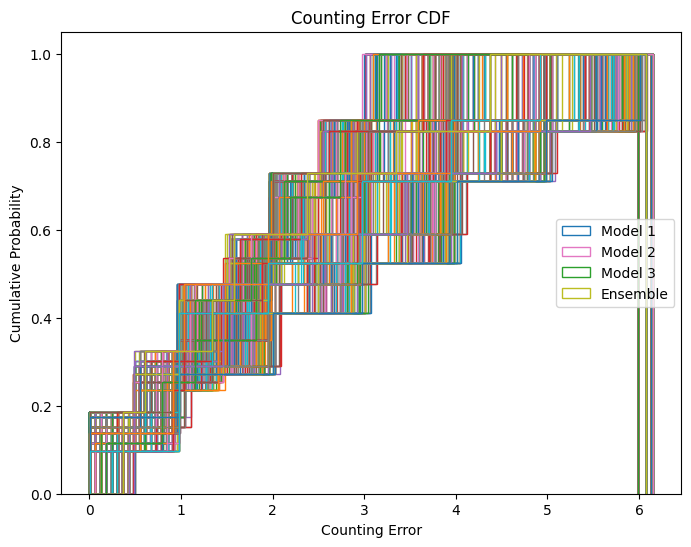

In [ ]:
import matplotlib.pyplot as plt

# Generate cumulative histogram of counting errors
n_bins = 10
fig, ax = plt.subplots(figsize=(8, 6))
n, bins, patches = ax.hist(counting_error_model1, n_bins, density=True, histtype='step', cumulative=True, label='LGBM')
n, bins, patches = ax.hist(counting_error_model2, n_bins, density=True, histtype='step', cumulative=True, label='XGB')
n, bins, patches = ax.hist(counting_error_model3, n_bins, density=True, histtype='step', cumulative=True, label='RF')

# Add labels and legend
ax.set_xlabel('Counting Error')
ax.set_ylabel('Cumulative Probability')
ax.set_title('Counting Error CDF')
ax.legend(loc='right')
plt.show()


In [ ]:
model1.fit(X, y)

/usr/local/lib/python3.10/dist-packages/lightgbm/basic.py:179: UserWarning: Converting column-vector to 1d array
  _log_warning('Converting column-vector to 1d array')


LGBMRegressor()

In [ ]:
model2.fit(X, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=100, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [ ]:
model3.fit(X, y)

<ipython-input-25-59d746a3720f>:1: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  model3.fit(X, y)


RandomForestRegressor(random_state=0)

In [ ]:
ensemble.fit(X, y)

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


BaggingRegressor(base_estimator=LGBMRegressor(num_leaves=16), n_estimators=5,
                 random_state=42)

In [ ]:
rscore1=model1.score(X_val, y_val)
rscore2=model2.score(X_val, y_val)
rscore3=model3.score(X_val, y_val)
rscore4=ensemble.score(X_val, y_val)

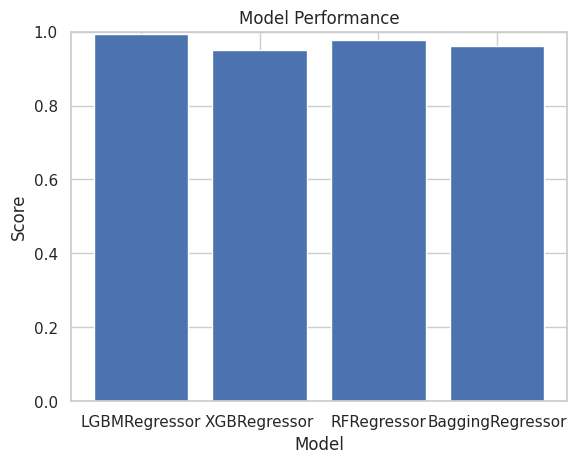

In [ ]:
models = ['LGBMRegressor', 'XGBRegressor', 'RFRegressor', 'BaggingRegressor']
scores = [rscore1, rscore2, rscore3, rscore4]

plt.bar(models, scores)
plt.ylim(0, 1)
plt.title('Model Performance')
plt.xlabel('Model')
plt.ylabel('Score')
plt.show()

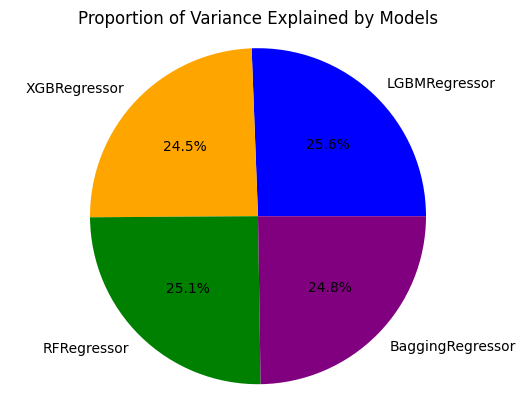

In [ ]:
proportions = [rscore1, rscore2, rscore3, rscore4]
proportions = np.array(proportions) / np.sum(proportions)

# Create the pie chart
labels = ['LGBMRegressor', 'XGBRegressor', 'RFRegressor', 'BaggingRegressor']
colors = ['blue', 'orange', 'green', 'purple']
plt.pie(proportions, labels=labels, colors=colors, autopct='%1.1f%%')
plt.axis('equal')
plt.title('Proportion of Variance Explained by Models')
plt.show()

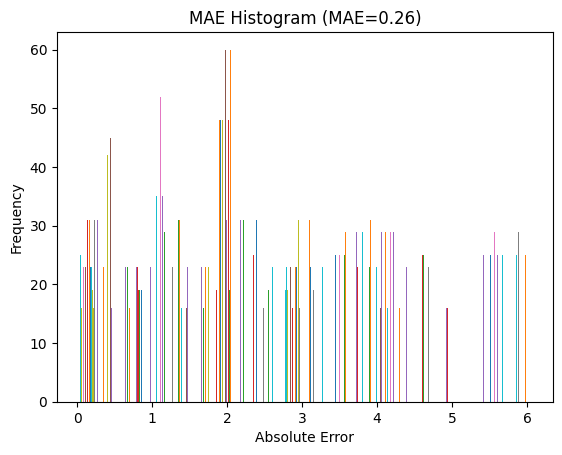

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# assuming X_test and y_test are the test data
y_pred = ensemble.predict(X_val)
mae = mean_absolute_error(y_val, y_pred)
abs_errors = abs(y_val - y_pred)

plt.hist(abs_errors, bins=20)
plt.xlabel('Absolute Error')
plt.ylabel('Frequency')
plt.title('MAE Histogram (MAE={:.2f})'.format(mae))
plt.show()


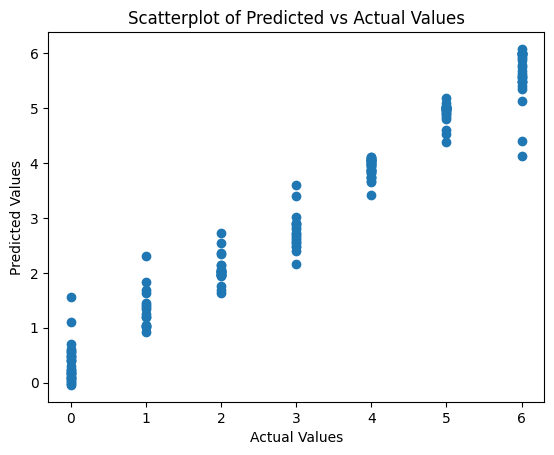

In [ ]:
import matplotlib.pyplot as plt

# assuming X_test and y_test are the test data
y_pred = ensemble.predict(X_val)

plt.scatter(y_val, y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Scatterplot of Predicted vs Actual Values')
plt.show()


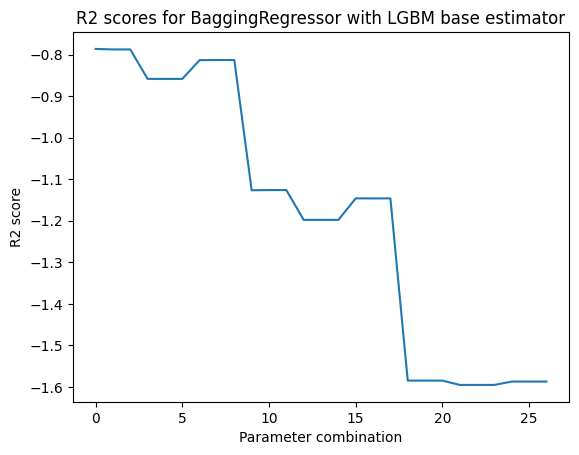

In [ ]:
import matplotlib.pyplot as plt

# Assuming the grid_search object has been fitted to the data

# Get the R2 scores for each parameter combination
r2_scores = grid_search.cv_results_['mean_test_score']

# Plot the R2 scores as a line plot
plt.plot(r2_scores)
plt.xlabel('Parameter combination')
plt.ylabel('R2 score')
plt.title('R2 scores for BaggingRegressor with LGBM base estimator')
plt.show()


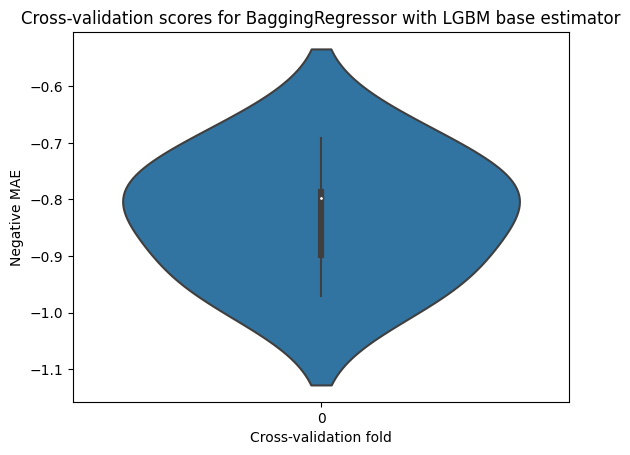

In [ ]:
import seaborn as sns

# Assuming scores is a list of cross-validation scores obtained from cross_val_score()

# Create a violinplot of the scores
sns.violinplot(scores)
plt.xlabel('Cross-validation fold')
plt.ylabel('Negative MAE')
plt.title('Cross-validation scores for BaggingRegressor with LGBM base estimator')
plt.show()


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_bagging.py:508: DataConversion

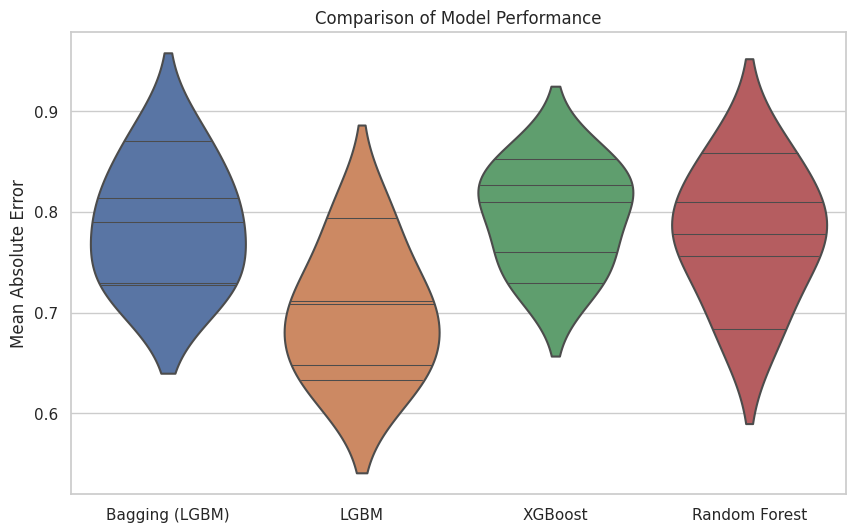

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a list of models and their names
models = [(ensemble, 'Bagging (LGBM)'),
          (model1, 'LGBM'),
          (model2, 'XGBoost'),
          (model3, 'Random Forest')]

# Use cross-validation to get the MAE scores for each model
scores = []
names = []
for model, name in models:
    score = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
    scores.append(score)
    names.append(name)

# Create a violin plot of the scores for each model
sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=scores, inner='stick', scale='width', ax=ax)
ax.set_xticklabels(names)
ax.set_ylabel('Mean Absolute Error')
ax.set_title('Comparison of Model Performance')
plt.show()


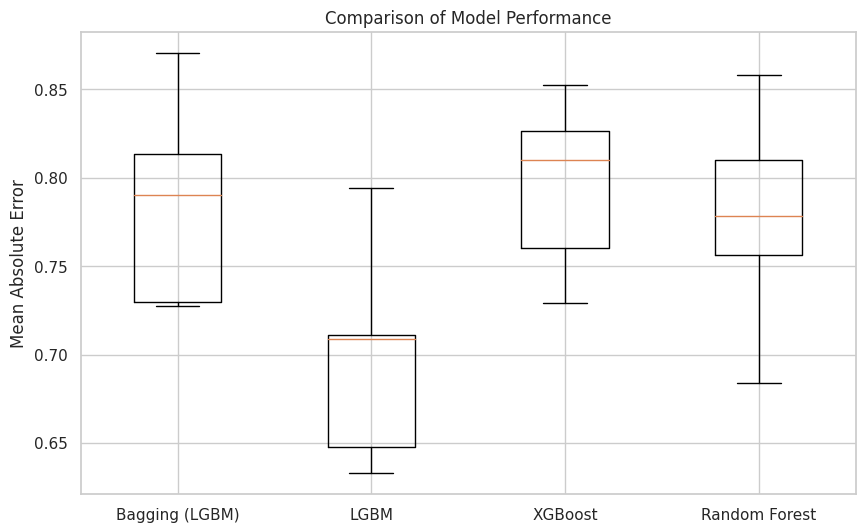

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(scores, labels=names, showfliers=False)
ax.set_ylabel('Mean Absolute Error')
ax.set_title('Comparison of Model Performance')
plt.show()